# Ablation studies

Change one design choice and compare control reward. HalfCheetah target: 12,000.

3 training runs × 100 tests per target. SD: variation between run averages. Middle reward: middle of the three run medians.

In [ ]:
!pip install -q numpy==2.5.3 pandas==3.0.6 matplotlib==3.11.2 wandb==0.31.0

Place `results.zip` in the input files or `assets/`.

In [1]:
from pathlib import Path
import json
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

archive = Path("assets/results.zip")
if not archive.exists():
    archive = next(Path("/kaggle/input").rglob("results.zip"))
with zipfile.ZipFile(archive) as f:
    f.extractall("results")
figures = Path("figures/ablation")
figures.mkdir(parents=True, exist_ok=True)
seeds = [42, 43, 44]
colors = {"DT": "#147BE8", "DeMa": "#E52666", "CQL": "#15945B",
          "SSM": "#7753D6", "DeMa + SER": "#F09500"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "text.color": "black", "axes.labelcolor": "black",
                     "xtick.color": "black", "ytick.color": "black",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.facecolor": "white"})

def load(prefix, seed):
    return json.loads((Path("results") / f"{prefix}_seed{seed}.json").read_text())

def evaluations(prefix, model, target):
    rows = []
    for seed in seeds:
        data = load(prefix, seed)
        row = data["evaluation"] if model == "CQL" else data["models"][model]["evaluations"][str(float(target))]
        scores = np.asarray(row["return_scores"])
        assert len(scores) == row["rollouts"] == 100
        assert np.isfinite(scores).all()
        assert np.isclose(scores.mean(), row["return_mean"])
        assert np.isclose(np.median(scores), row["return_median"])
        rows.append(row)
    return rows

def summary(label, rows, target, maze=False):
    means = [r["return_mean"] for r in rows]
    result = {"Model": label, "Target": target,
              "Average reward": np.mean(means), "SD": np.std(means, ddof=1),
              "Middle reward": np.median([r["return_median"] for r in rows])}
    if maze:
        result["Goal arrival (%)"] = sum(np.count_nonzero(np.asarray(r["return_scores"]) > 0) for r in rows) / 3
    return result

def table(rows):
    display(pd.DataFrame(rows).style.format(precision=1, thousands=","))

def save(fig, name):
    fig.savefig(figures / name, dpi=400)
    plt.show()
    plt.close(fig)

def bars(ax, labels, values, palette, title, ylabel, percent=False, samples=None):
    ax.bar(range(len(labels)), values, color=palette, width=0.58)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(title, fontweight="bold", pad=16)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    ax.set_ylim(0, 112 if percent else max(values) * 1.29)
    if percent:
        ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    for i, value in enumerate(values):
        height = max(value, max(samples[i])) if samples is not None else value
        ax.annotate(f"{value:.1f}%" if percent else f"{value:,.0f}",
                    (i, height), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=13, fontweight="bold")
    if samples is not None:
        for i, points in enumerate(samples):
            ax.scatter(i + np.linspace(-0.12, 0.12, len(points)), points,
                       s=26, facecolor="white", edgecolor="black", zorder=3)
        ax.set_ylim(0, max(max(points) for points in samples) * 1.30)

def losses(cases, name):
    fig, axes = plt.subplots((len(cases) + 1) // 2, 2, figsize=(11, 3.7 * ((len(cases) + 1) // 2)),
                             layout="constrained", squeeze=False)
    for ax, (title, prefix, model) in zip(axes.flat, cases):
        histories = [load(prefix, seed)["models"][model]["loss_history"] for seed in seeds]
        for key, label, color, line in [("loss", "Training", "#147BE8", "-"),
                                         ("validation_loss", "Validation", "#D87700", "--")]:
            steps = sorted(set.intersection(*[{p["step"] for p in h if key in p} for h in histories]))
            values = np.mean([[next(p[key] for p in h if p["step"] == step) for step in steps] for h in histories], axis=0)
            choose = np.asarray(steps) >= 10000
            ax.plot(np.asarray(steps)[choose] / 1000, values[choose], color=color,
                    linestyle=line, linewidth=2.4, label=label)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Training updates (thousands)")
        ax.set_ylabel("Action prediction loss")
        ax.set_xlim(10, 100)
        ax.set_xticks([10, 50, 100])
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    for row in axes:
        visible = [ax for ax in row if ax.has_data()]
        top = max(ax.get_ylim()[1] for ax in visible)
        for ax in visible:
            ax.set_ylim(0, top * 1.10)
    for ax in list(axes.flat)[len(cases):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False, fontsize=11)
    save(fig, name)


## Settings and results

In [2]:
files = [("DT", "Original", "final_dt", "Decision Transformer"),
         ("DeMa", "Original", "final_dema", "DeMa"),
         ("DT", "Grouped", "axis2_dt", "Decision Transformer"),
         ("DeMa", "Grouped", "axis2_dema", "DeMa"),
         ("DT", "Pre-norm", "axis3_dt", "Decision Transformer"),
         ("DeMa", "Pre-norm", "axis3_dema", "DeMa"),
         ("DeMa", "Step labels", "pe_dema_timestep", "DeMa"),
         ("DeMa", "Small init", "pe_rescale_dema", "DeMa")]
data = {}
rows = []
for label, case, prefix, model in files:
    data[label, case] = evaluations(prefix, model, 12000)
    row = summary(label, data[label, case], 12000)
    row["Setting"] = case
    rows.append(row)
table(rows)
settings = []
for label, case, prefix, model in files:
    d = load(prefix, seeds[0])
    settings.append({"Model": label, "Setting": case, "Input layout": d["token_layout"],
                     "Pre-norm": d["norm_first"] if label == "DT" else d["dema_norm_first"],
                     "Step labels": d["dt_uses_timestep_embedding"] if label == "DT" else d["dema_uses_timestep_embedding"],
                     "Parameters": data[label, case][0]["parameters"]})
display(pd.DataFrame(settings))

,Model,Target,Average reward,SD,Middle reward,Setting
0,DT,"12,000","10,291.1","2,349.5","13,567.7",Original
1,DeMa,"12,000","12,553.8",383.5,"12,914.8",Original
2,DT,"12,000","10,797.5","1,893.5","13,013.6",Grouped
3,DeMa,"12,000","11,637.5","1,103.1","13,012.2",Grouped
4,DT,"12,000","13,859.1",612.4,"14,515.3",Pre-norm
5,DeMa,"12,000","12,368.5",609.0,"12,841.5",Pre-norm
6,DeMa,"12,000","1,056.2",107.8,911.6,Step labels
7,DeMa,"12,000","8,717.2",373.2,"10,133.8",Small init


,Model,Setting,Input layout,Pre-norm,Step labels,Parameters
0,DT,Original,interleaved,False,False,599302
1,DeMa,Original,interleaved,False,False,750598
2,DT,Grouped,grouped,False,False,599302
3,DeMa,Grouped,grouped,False,False,750598
4,DT,Pre-norm,interleaved,True,False,599302
5,DeMa,Pre-norm,interleaved,True,False,750598
6,DeMa,Step labels,interleaved,False,True,878598
7,DeMa,Small init,interleaved,False,True,878598


## DeMa design choices

Bars: averages. Circles: three training runs. Original DeMa has the highest average among its five settings.

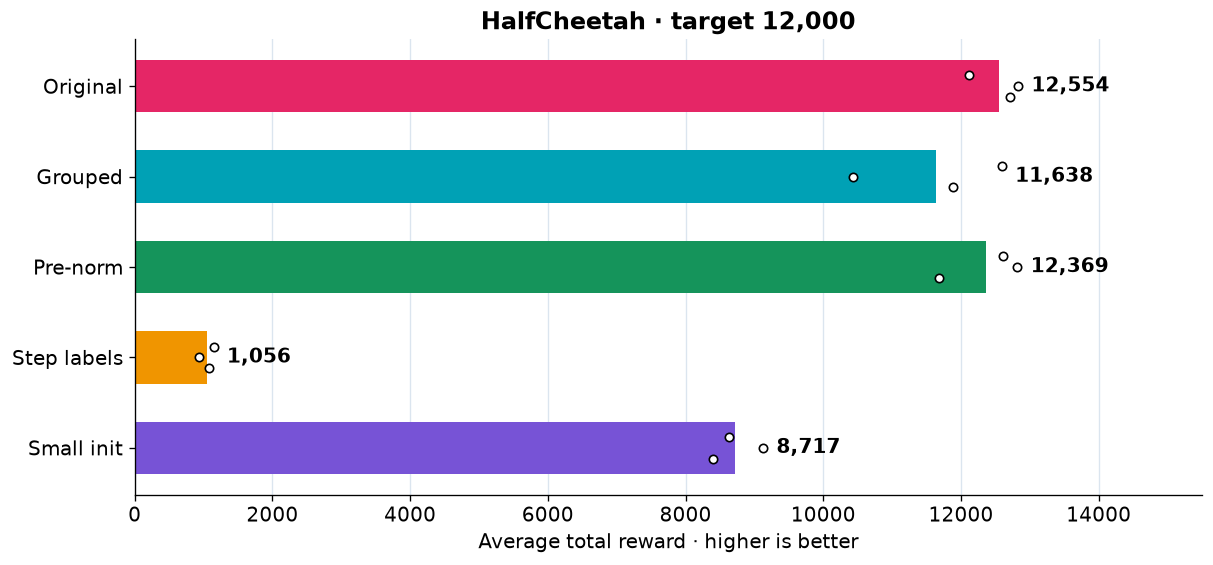

In [3]:
cases = ["Original", "Grouped", "Pre-norm", "Step labels", "Small init"]
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
palette = [colors["DeMa"], "#00A1B5", "#15945B", "#F09500", "#7753D6"]
for i, case in enumerate(cases):
    means = [r["return_mean"] for r in data["DeMa", case]]
    value = np.mean(means)
    ax.barh(i, value, color=palette[i], height=0.58)
    ax.scatter(means, i + np.linspace(-0.12, 0.12, 3), s=25, facecolor="white", edgecolor="black", zorder=3)
    ax.annotate(f"{value:,.0f}", (max(means + [value]), i), xytext=(8, 0), textcoords="offset points", va="center", fontweight="bold")
ax.set_yticks(range(len(cases)), cases)
ax.invert_yaxis()
ax.set_xlim(0, 15500)
ax.set_xlabel("Average total reward · higher is better")
ax.set_title("HalfCheetah · target 12,000", fontweight="bold")
ax.set_axisbelow(True)
ax.grid(axis="x", color="#DBE5EF")
save(fig, "design.png")

## Input grouping and normalization

Grouped: one combined input per step. Pre-norm: normalize before each block.

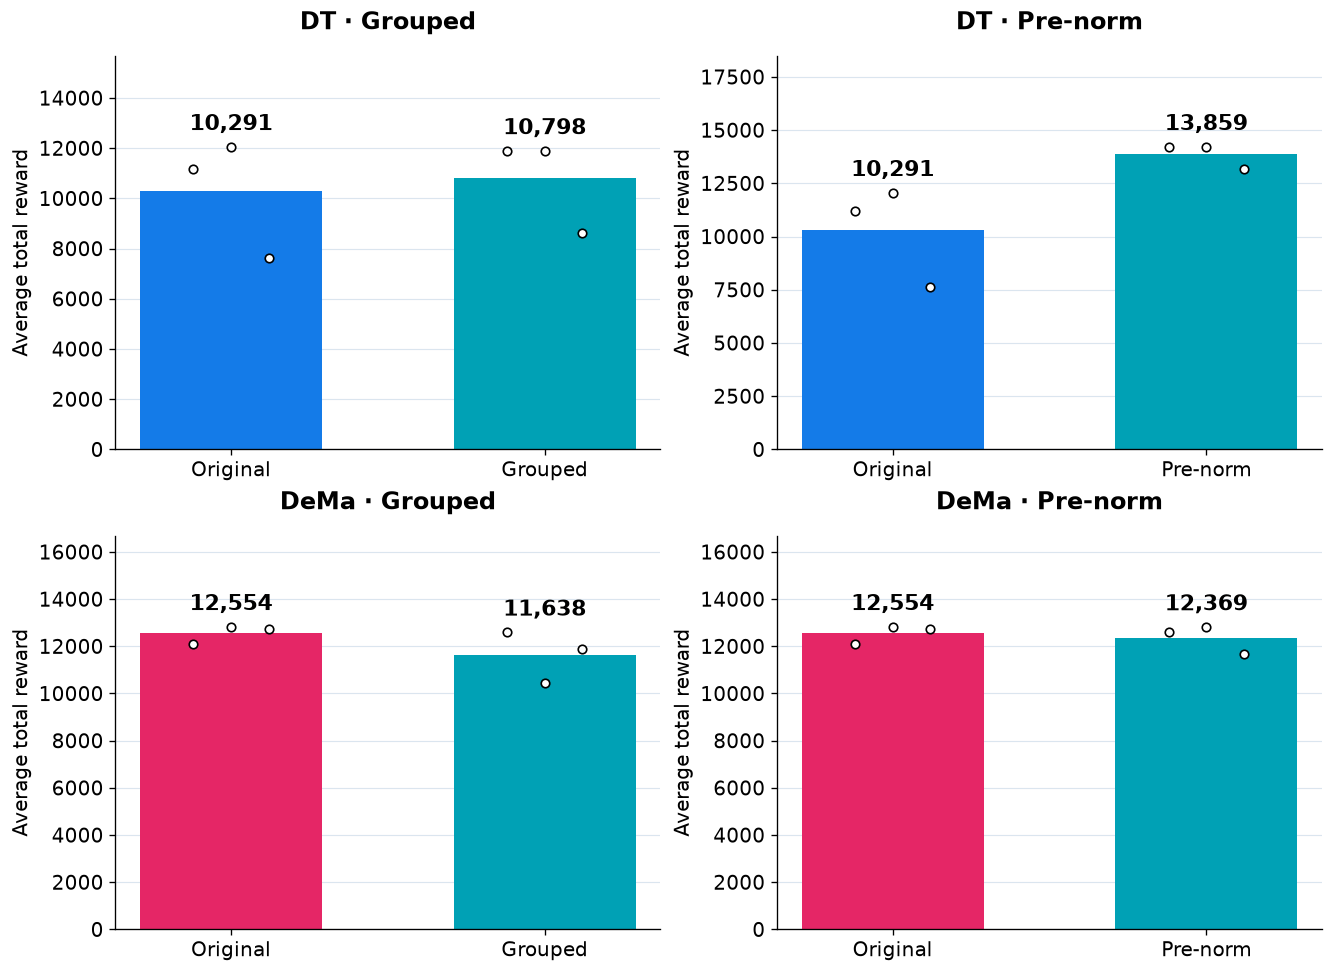

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for row, label in enumerate(["DT", "DeMa"]):
    for col, case in enumerate(["Grouped", "Pre-norm"]):
        cases = ["Original", case]
        samples = [[r["return_mean"] for r in data[label, c]] for c in cases]
        bars(axes[row, col], cases, [np.mean(v) for v in samples], [colors[label], "#00A1B5"],
             f"{label} · {case}", "Average total reward", samples=samples)
save(fig, "layout_norm.png")

## Input-grouping learning curves

Average of three training runs, shown from 10,000 updates.

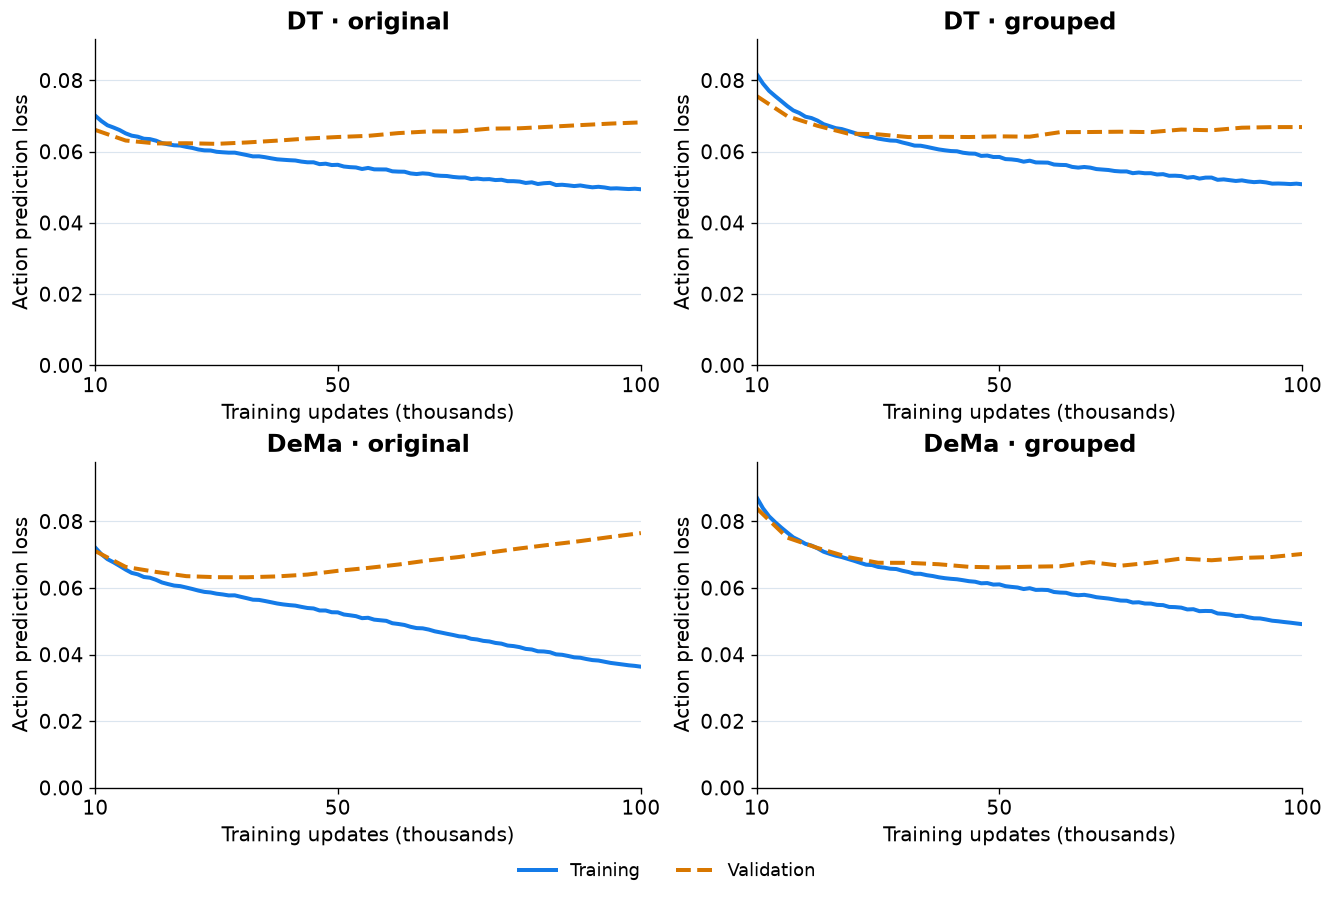

In [5]:
losses([("DT · original", "final_dt", "Decision Transformer"),
        ("DT · grouped", "axis2_dt", "Decision Transformer"),
        ("DeMa · original", "final_dema", "DeMa"),
        ("DeMa · grouped", "axis2_dema", "DeMa")], "layout_loss.png")

## Normalization learning curves

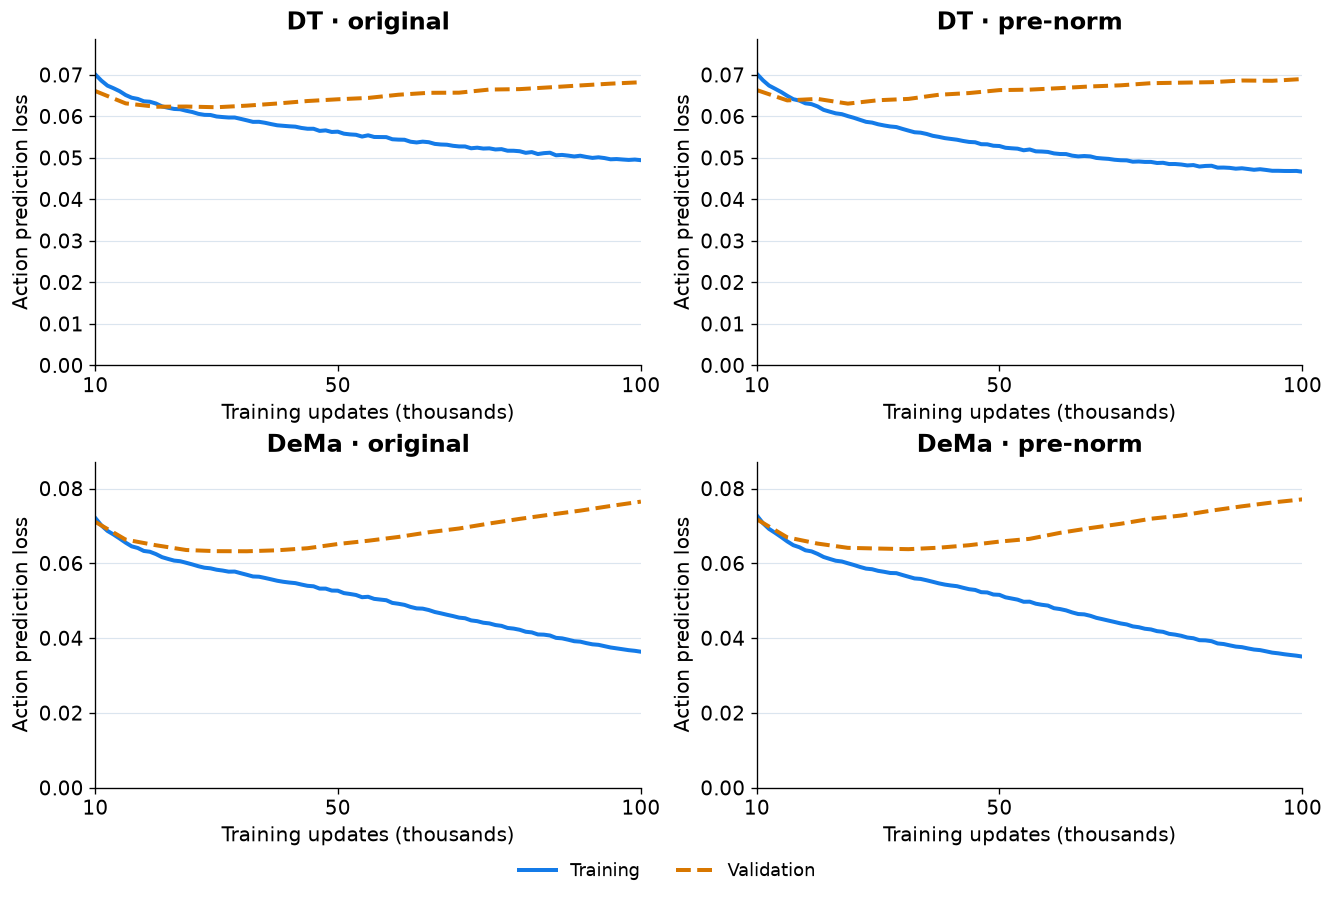

In [6]:
losses([("DT · original", "final_dt", "Decision Transformer"),
        ("DT · pre-norm", "axis3_dt", "Decision Transformer"),
        ("DeMa · original", "final_dema", "DeMa"),
        ("DeMa · pre-norm", "axis3_dema", "DeMa")], "norm_loss.png")

## Step-label learning curves

Small initialization sets step-embedding standard deviation to 0.02.

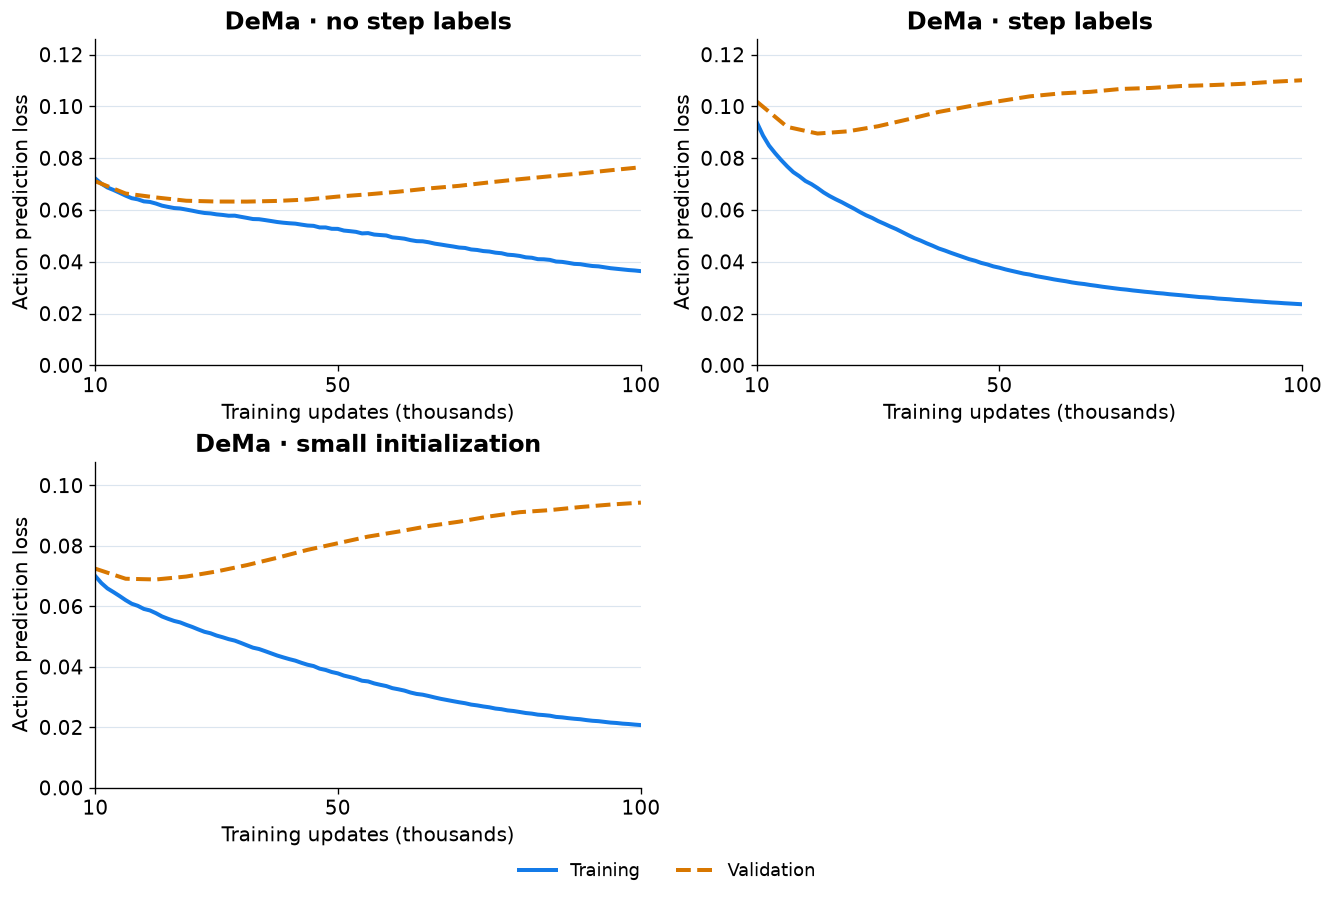

In [7]:
losses([("DeMa · no step labels", "final_dema", "DeMa"),
        ("DeMa · step labels", "pe_dema_timestep", "DeMa"),
        ("DeMa · small initialization", "pe_rescale_dema", "DeMa")], "step_loss.png")

## Windowed and recurrent DeMa

Same three trained models, two evaluation modes. A window uses the latest 20 steps; recurrent memory carries state forward.

,Model,Target,Average reward,SD,Middle reward
0,20-step window,"12,000","12,553.8",383.5,"12,914.8"
1,Recurrent memory,"12,000","12,347.3",368.8,"12,732.2"


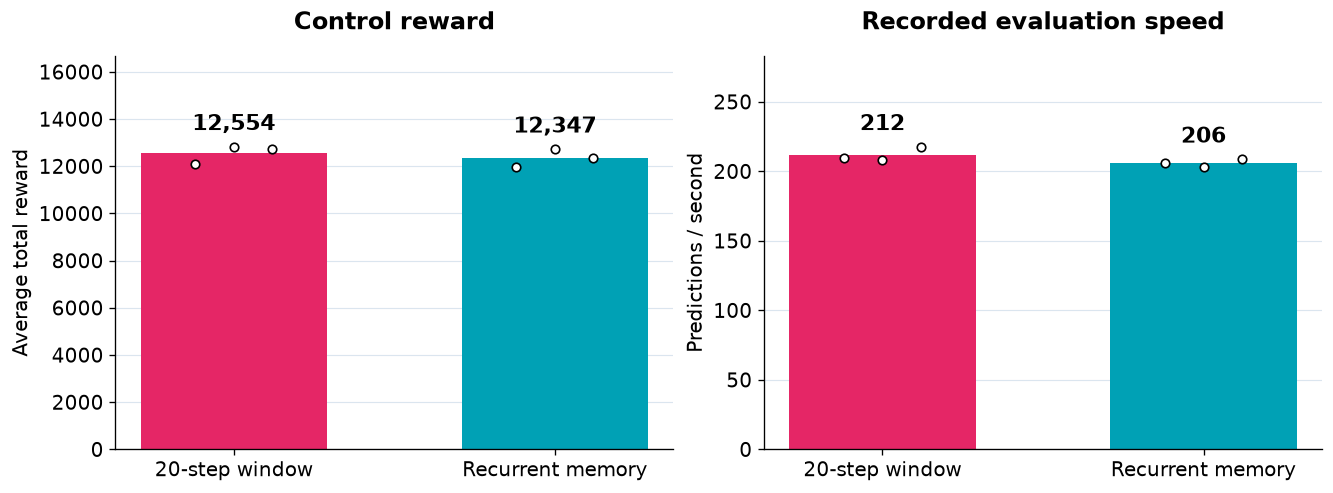

In [8]:
modes = {"20-step window": [], "Recurrent memory": []}
for seed in seeds:
    model = load("final_dema", seed)["models"]["DeMa"]
    modes["20-step window"].append(model["evaluations"]["12000.0"])
    modes["Recurrent memory"].append(model["recurrent"]["12000.0"])
table([summary(label, rows, 12000) for label, rows in modes.items()])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
labels = list(modes)
for ax, field, title, ylabel in [(axes[0], "return_mean", "Control reward", "Average total reward"),
                                  (axes[1], "decisions_per_second", "Recorded evaluation speed", "Predictions / second")]:
    samples = [[r[field] for r in modes[label]] for label in labels]
    bars(ax, labels, [np.mean(v) for v in samples], [colors["DeMa"], "#00A1B5"], title, ylabel, samples=samples)
save(fig, "memory_modes.png")

## W&B histories

In [9]:
names = [f"{prefix}_seed{seed}" for label, case, prefix, model in files for seed in seeds]
logs = {}
if os.environ.get("WANDB_API_KEY"):
    import wandb
    api = wandb.Api(timeout=30)
    entity = os.environ.get("WANDB_ENTITY") or api.default_entity
    project = os.environ.get("WANDB_PROJECT", "dema-vs-dt")
    for run in api.runs(f"{entity}/{project}"):
        if run.name in names:
            logs[run.name] = list(run.scan_history(page_size=200))
    print(f"Loaded {len(logs)} run histories")